In [1]:
# ======Code by Dr. Rahul M. Dhokane, PRAVARA SVIT, NASHIK=============
# EXPERIMENT: K-Means & Hierarchical Clustering on sales_data_sample.csv
# =====================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as shc

# Set aesthetic visual style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [3]:
# ---------------------------------------------------------------------
# Step 1: Load and Inspect Dataset
# ---------------------------------------------------------------------
# Note: 'latin1' encoding is used to avoid UnicodeDecodeError on this Kaggle dataset
file_path = 'sales_data_sample.csv'
df = pd.read_csv(file_path, encoding='latin1')

print("--- Dataset Overview ---")
print(df.head())
print("\n--- Dataset Info ---")
print(df.info())
print("\n--- Missing Values Check ---")
print(df.isnull().sum())

--- Dataset Overview ---
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue 

In [4]:
# ---------------------------------------------------------------------
# Step 2: Data Preprocessing & Feature Selection
# ---------------------------------------------------------------------
# Select continuous numerical columns relevant for sales segmentation
features = ['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']
data_num = df[features].dropna()

# Standardize features (Mean = 0, Std Dev = 1) because distance-based
# algorithms are sensitive to feature scales.
scaler = StandardScaler()
scaled_features = scaler.fit_transform(data_num)

scaled_df = pd.DataFrame(scaled_features, columns=features)
print("\n--- Scaled Features Preview ---")
print(scaled_df.head())


--- Scaled Features Preview ---
   QUANTITYORDERED  PRICEEACH     SALES      MSRP
0        -0.522891   0.596978 -0.370825 -0.142246
1        -0.112201  -0.114450 -0.427897 -0.142246
2         0.606505   0.549384  0.179443 -0.142246
3         1.017195  -0.019759  0.104701 -0.142246
4         1.427884   0.810158  0.896740 -0.142246


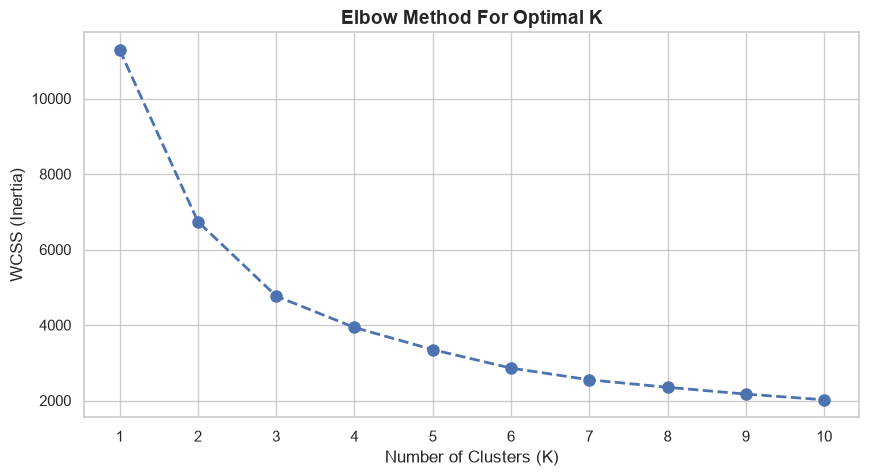

In [5]:
# ---------------------------------------------------------------------
# Step 3: Determine Optimal K using the Elbow Method
# ---------------------------------------------------------------------
wcss = []  # Within-Cluster Sum of Squares
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(scaled_features)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(10, 5))
plt.plot(k_range, wcss, marker='o', linestyle='--', color='b', linewidth=2, markersize=8)
plt.title('Elbow Method For Optimal K', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clusters (K)', fontsize=12)
plt.ylabel('WCSS (Inertia)', fontsize=12)
plt.xticks(k_range)
plt.grid(True)
plt.show()

In [6]:
# ---------------------------------------------------------------------
# Step 4: Train K-Means Model with Optimal Clusters
# ---------------------------------------------------------------------
# Based on the Elbow plot, optimal K is typically selected around 3 or 4
optimal_k = 3

kmeans_model = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans_model.fit_predict(scaled_features)

# Print Silhouette Score to evaluate quality
score = silhouette_score(scaled_features, df['KMeans_Cluster'])
print(f"\nK-Means Silhouette Score (K={optimal_k}): {score:.4f}")

# Display Mean Values per Cluster
print("\n--- K-Means Cluster Profiles (Mean Values) ---")
cluster_summary = df.groupby('KMeans_Cluster')[features].mean()
print(cluster_summary)


K-Means Silhouette Score (K=3): 0.3509

--- K-Means Cluster Profiles (Mean Values) ---
                QUANTITYORDERED  PRICEEACH        SALES        MSRP
KMeans_Cluster                                                     
0                     35.208205  59.551169  2101.076482   64.145641
1                     43.723005  97.479261  5720.080669  127.893192
2                     27.597390  95.435090  3123.062801  113.266064


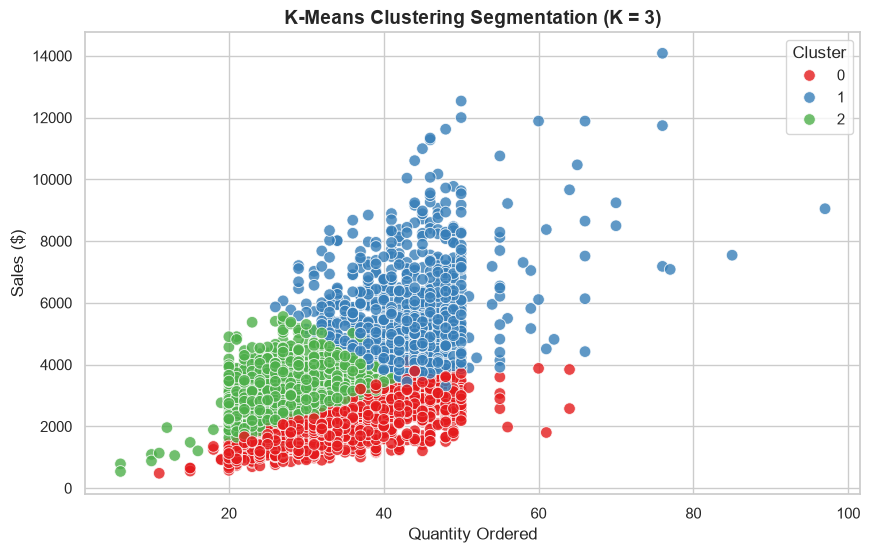

In [7]:
# ---------------------------------------------------------------------
# Step 5: Visualize K-Means Clusters
# ---------------------------------------------------------------------
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='QUANTITYORDERED',
    y='SALES',
    hue='KMeans_Cluster',
    palette='Set1',
    s=70,
    alpha=0.8
)
plt.title(f'K-Means Clustering Segmentation (K = {optimal_k})', fontsize=14, fontweight='bold')
plt.xlabel('Quantity Ordered', fontsize=12)
plt.ylabel('Sales ($)', fontsize=12)
plt.legend(title='Cluster')
plt.show()

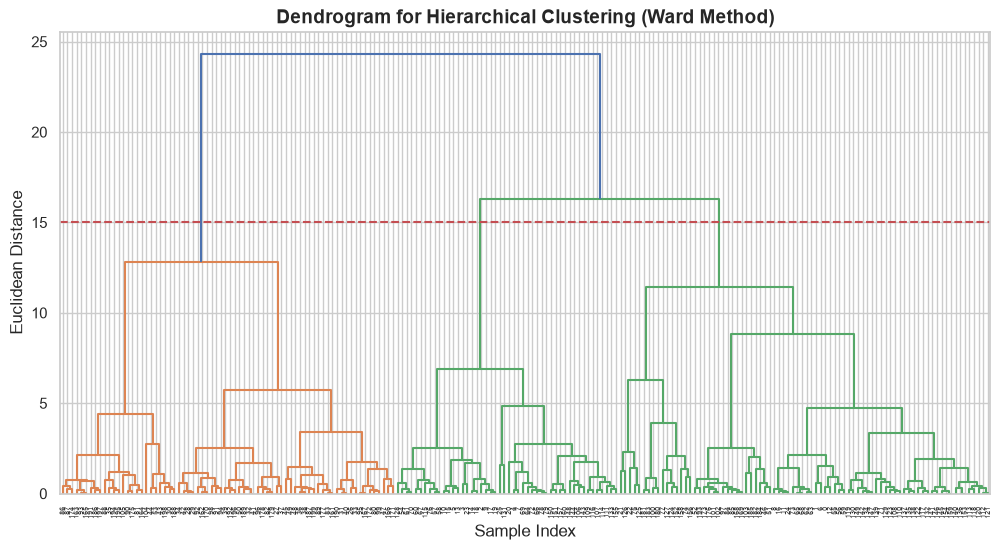

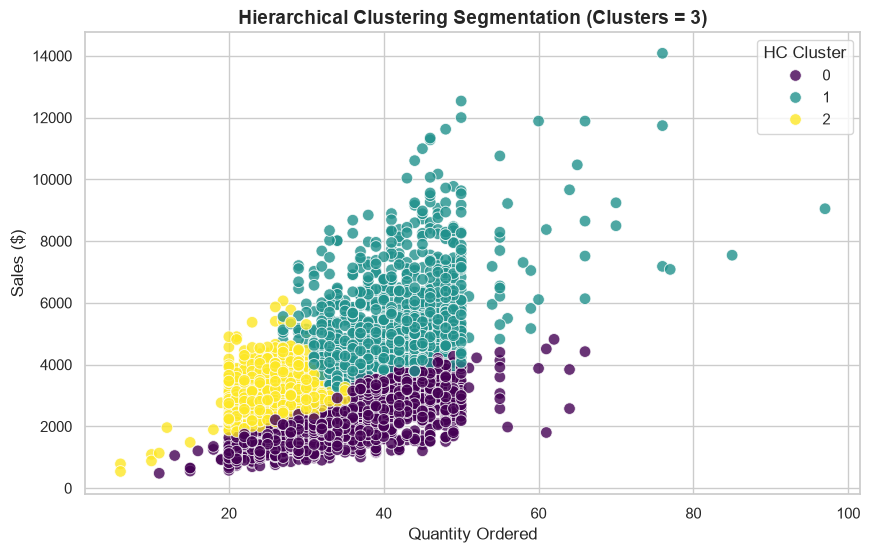

In [8]:
# ---------------------------------------------------------------------
# Step 6: Hierarchical Clustering (Dendrogram & Agglomerative)
# ---------------------------------------------------------------------
# Plot Dendrogram (Sampling 200 data points for clean visualization)
sample_scaled = scaled_features[:200]

plt.figure(figsize=(12, 6))
plt.title('Dendrogram for Hierarchical Clustering (Ward Method)', fontsize=14, fontweight='bold')
plt.xlabel('Sample Index')
plt.ylabel('Euclidean Distance')
dend = shc.dendrogram(shc.linkage(sample_scaled, method='ward'))
plt.axhline(y=15, color='r', linestyle='--')  # Optional cut line reference
plt.show()

# Fit Agglomerative Hierarchical Model
hc_model = AgglomerativeClustering(n_clusters=optimal_k, metric='euclidean', linkage='ward')
df['HC_Cluster'] = hc_model.fit_predict(scaled_features)

# Visualize Hierarchical Clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='QUANTITYORDERED',
    y='SALES',
    hue='HC_Cluster',
    palette='viridis',
    s=70,
    alpha=0.8
)
plt.title(f'Hierarchical Clustering Segmentation (Clusters = {optimal_k})', fontsize=14, fontweight='bold')
plt.xlabel('Quantity Ordered', fontsize=12)
plt.ylabel('Sales ($)', fontsize=12)
plt.legend(title='HC Cluster')
plt.show()